In [6]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
# Load the Breast Cancer dataset
data = load_breast_cancer(as_frame=True)

# Separate features and target
X = data.data
y = data.target

# Display dataset information
print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)

print("\nFirst five rows:")
display(X.head())

print("\nClass distribution:")
print(y.value_counts())

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Class distribution:
target
1    357
0    212
Name: count, dtype: int64


In [8]:
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


In [9]:
baseline_model = RandomForestClassifier(random_state=42)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline F1-score:",
      f1_score(y_test, baseline_predictions))

Baseline accuracy: 0.956140350877193
Baseline F1-score: 0.9655172413793104


In [10]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

total_combinations = (
    len(param_grid["n_estimators"])
    * len(param_grid["max_depth"])
    * len(param_grid["min_samples_split"])
)

print("Total combinations:", total_combinations)


Total combinations: 18


In [11]:
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

start_time = time.perf_counter()

grid_search.fit(X_train, y_train)

grid_time = time.perf_counter() - start_time

print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation accuracy:")
print(grid_search.best_score_)

print("\nSearch time:")
print(round(grid_time, 3), "seconds")

Best hyperparameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}

Best cross-validation accuracy:
0.9604395604395606

Search time:
11.064 seconds


In [12]:
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

start_time = time.perf_counter()

grid_search.fit(X_train, y_train)

grid_time = time.perf_counter() - start_time

print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation accuracy:")
print(grid_search.best_score_)

print("\nSearch time:")
print(round(grid_time, 3), "seconds")

Best hyperparameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}

Best cross-validation accuracy:
0.9604395604395606

Search time:
11.231 seconds


In [14]:

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=10,
    scoring="accuracy",
    cv=5,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

start_time = time.perf_counter()

random_search.fit(X_train, y_train)

random_time = time.perf_counter() - start_time

print("Best hyperparameters:")
print(random_search.best_params_)

print("\nBest cross-validation accuracy:")
print(random_search.best_score_)

print("\nSearch time:")
print(round(random_time, 3), "seconds")


Best hyperparameters:
{'n_estimators': 200, 'min_samples_split': 2, 'max_depth': None}

Best cross-validation accuracy:
0.9604395604395606

Search time:
1.991 seconds


In [15]:

# Get the best models found by each search
grid_model = grid_search.best_estimator_
random_model = random_search.best_estimator_

# Make predictions on the same test set
grid_predictions = grid_model.predict(X_test)
random_predictions = random_model.predict(X_test)

# Compare final test performance
comparison = pd.DataFrame({
    "Search Method": ["Grid Search", "Random Search"],
    "Best CV Accuracy": [
        grid_search.best_score_,
        random_search.best_score_
    ],
    "Test Accuracy": [
        accuracy_score(y_test, grid_predictions),
        accuracy_score(y_test, random_predictions)
    ],
    "Test F1 Score": [
        f1_score(y_test, grid_predictions),
        f1_score(y_test, random_predictions)
    ],
    "Search Time (seconds)": [
        grid_time,
        random_time
    ]
})

display(comparison.round(4))


,Search Method,Best CV Accuracy,Test Accuracy,Test F1 Score,Search Time (seconds)
0,Grid Search,0.9604,0.9561,0.9655,11.2307
1,Random Search,0.9604,0.9561,0.9655,1.9905


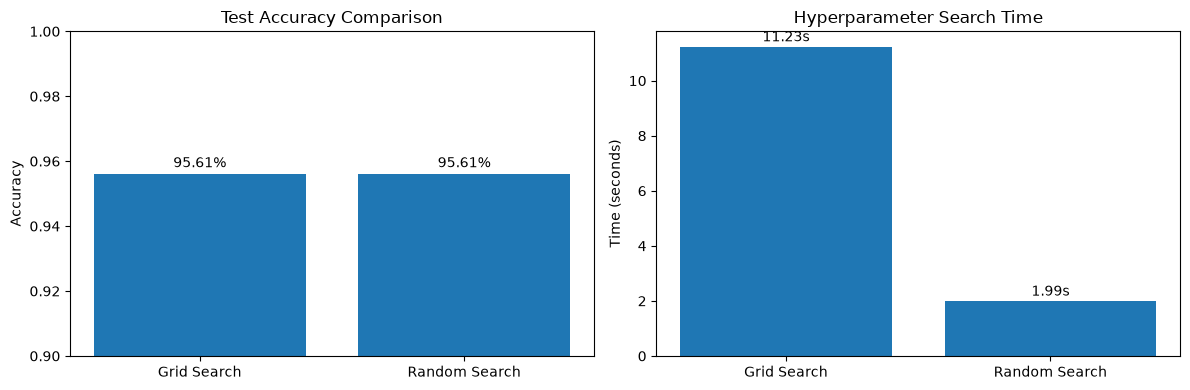

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Chart 1: Compare test accuracy
methods = comparison["Search Method"]
accuracies = comparison["Test Accuracy"]

axes[0].bar(methods, accuracies)
axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.90, 1.00)

for i, value in enumerate(accuracies):
    axes[0].text(i, value + 0.002, f"{value:.2%}", ha="center")

# Chart 2: Compare search time
times = comparison["Search Time (seconds)"]

axes[1].bar(methods, times)
axes[1].set_title("Hyperparameter Search Time")
axes[1].set_ylabel("Time (seconds)")

for i, value in enumerate(times):
    axes[1].text(i, value + 0.2, f"{value:.2f}s", ha="center")

plt.tight_layout()
plt.show()


In [17]:

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_f1 = f1_score(y_test, baseline_predictions)

all_models = pd.DataFrame({
    "Model": [
        "Baseline Random Forest",
        "Grid Search",
        "Random Search"
    ],
    "Test Accuracy": [
        baseline_accuracy,
        accuracy_score(y_test, grid_predictions),
        accuracy_score(y_test, random_predictions)
    ],
    "Test F1 Score": [
        baseline_f1,
        f1_score(y_test, grid_predictions),
        f1_score(y_test, random_predictions)
    ],
    "Search Time (seconds)": [
        0,
        grid_time,
        random_time
    ]
})

display(all_models.round(4))


,Model,Test Accuracy,Test F1 Score,Search Time (seconds)
0,Baseline Random Forest,0.9561,0.9655,0.0000
1,Grid Search,0.9561,0.9655,11.2307
2,Random Search,0.9561,0.9655,1.9905


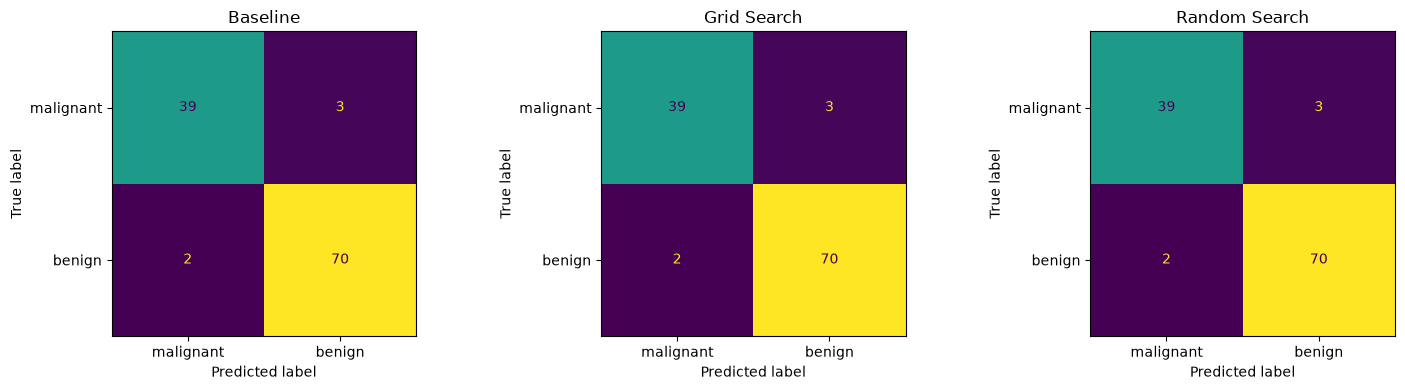

In [18]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models = [
    ("Baseline", baseline_predictions),
    ("Grid Search", grid_predictions),
    ("Random Search", random_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=data.target_names,
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [19]:

print("=" * 50)
print("HYPERPARAMETER TUNING PLAYGROUND")
print("=" * 50)

print(f"\nBaseline test accuracy: "
      f"{baseline_accuracy:.2%}")

print(f"Grid Search CV accuracy: "
      f"{grid_search.best_score_:.2%}")

print(f"Random Search CV accuracy: "
      f"{random_search.best_score_:.2%}")

print(f"\nGrid Search time: {grid_time:.2f} seconds")
print(f"Random Search time: {random_time:.2f} seconds")

speedup = grid_time / random_time
print(f"Random Search speedup: {speedup:.2f}x")

print("\nConclusion:")
if random_search.best_score_ >= grid_search.best_score_:
    print("Random Search matched or exceeded Grid Search CV accuracy.")
else:
    print("Grid Search achieved higher CV accuracy.")

print("Compare final test metrics before deciding which")
print("model performs best on unseen data.")


HYPERPARAMETER TUNING PLAYGROUND

Baseline test accuracy: 95.61%
Grid Search CV accuracy: 96.04%
Random Search CV accuracy: 96.04%

Grid Search time: 11.23 seconds
Random Search time: 1.99 seconds
Random Search speedup: 5.64x

Conclusion:
Random Search matched or exceeded Grid Search CV accuracy.
Compare final test metrics before deciding which
model performs best on unseen data.
